# Designed initializations that steer one neuron toward u_0

The reverse of the init-sweep question: instead of asking which random neuron captures u_0,
construct an init in which a chosen first-layer neuron (the *probe*) should move toward u_0
under population gradient flow, and check that it does. Construction and rationale are in
the docstring of `layer_lenses.designed_init`; in short: the probe starts orthogonal to every
ODT normal, 32 neurons sit exactly on the signed level-4 normals, the second layer wires the
probe (with weight +1 or -1) together with subsets of those level-4 neurons in four groups
that differ by root side and sign, the third layer is random 0/1, and the output is all ones.

Two facts to keep in mind when reading the numbers. The label is +1 iff the point's on-path
level-4 split is positive (leaf parity in `odt.py`). And a second-layer unit that receives
+ReLU(probe) is on whenever the probe is on, so it cannot carry any information about the
probe's input; only units with probe weight -1 gate on the level-4 features relative to the
probe. The sign rule that follows, verified below: informative groups on the root's right
subtree push the probe toward +u_0, on the left subtree toward -u_0.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
%load_ext autoreload
%autoreload 2
from layer_lenses.designed_init import (DesignedInitSpec, GROUP_ORDER, build_designed_model, first_layer_labels,
    logit_scale, neuron_trajectory_table, probe_gradient_report, run_designed_flow, sign_flip_variants,
    build_multiprobe_model, multiprobe_gradient_report, multiprobe_labels, two_probe_spec,
    SIX_PROBE_TARGETS, six_probe_spec, node_probe_groups, probe_target_report,
    HIERARCHY_TARGETS, HierarchyDesignSpec, build_hierarchy_model, hierarchy_probe_table)
import json
from layer_lenses.init_sweep import load_run, load_tree, sweep_capture_table, FIRST_LAYER_KEY
from layer_lenses.init_sweep import SweepRunSpec, build_data, build_tree

RESULTS = Path("../results/designed_init")
tree = build_tree(SweepRunSpec(tree_seed=5178, data_seed=0, init_seed=0, batch_size=1))
x, y = build_data(SweepRunSpec(tree_seed=5178, data_seed=5178, init_seed=0, batch_size=1, n_train=1_000_000), tree)
EPS = 1e-3
DEVICE = "cuda"

## 1. The init, and the scale of its logits

In [2]:
spec = DesignedInitSpec(eps=EPS, seed=0)
model = build_designed_model(spec, tree)
for name, p in model.named_parameters():
    print(f"{name:24s} {tuple(p.shape)}  values in {sorted(set(np.round(p.detach().numpy().ravel(), 6)))[:3]} ... {sorted(set(np.round(p.detach().numpy().ravel(), 6)))[-2:]}")
print("first-layer labels:", first_layer_labels()[:5], "...", first_layer_labels()[-2:])
print("\nlogit RMS grows linearly with eps because layers 2-4 are O(1):")
for eps in (1e-4, 1e-3, 1e-2):
    print(f"  eps {eps:g}: {logit_scale(build_designed_model(DesignedInitSpec(eps=eps, seed=0), tree), x, device=DEVICE)}")

hidden_layers.0.weight   (40, 100)  values in [np.float32(-0.000408), np.float32(-0.00036), np.float32(-0.000335)] ... [np.float32(0.000333), np.float32(0.000335)]
hidden_layers.1.weight   (40, 40)  values in [np.float32(-1.0), np.float32(0.0), np.float32(1.0)] ... [np.float32(0.0), np.float32(1.0)]
hidden_layers.2.weight   (40, 40)  values in [np.float32(0.0), np.float32(1.0)] ... [np.float32(0.0), np.float32(1.0)]
output_layer.weight      (1, 40)  values in [np.float32(1.0)] ... [np.float32(1.0)]
first-layer labels: ['probe', '-u15', '+u15', '-u16', '+u16'] ... ['rand5', 'rand6']

logit RMS grows linearly with eps because layers 2-4 are O(1):


  eps 0.0001: {'rms_logit': 0.013771338388323784, 'max_abs_logit': 0.027838319540023804}
  eps 0.001: {'rms_logit': 0.13771338760852814, 'max_abs_logit': 0.27838319540023804}
  eps 0.01: {'rms_logit': 1.3771339654922485, 'max_abs_logit': 2.78383207321167}


## 2. Where the probe's gradient points at init

Per-group numbers zero the other groups' second-layer rows, which also changes the residue, so
they are indicative rather than exact. Energy fractions are of the unit-normalized negative
gradient.

In [3]:
rep = probe_gradient_report(model, x, y, tree, device=DEVICE)
rows = []
for k, v in rep.items():
    c = v["odt_coords"]
    rows.append({"which": k, "grad_norm": v["grad_norm"], "cos(-g, u0)": v["cos_u0"], "off-span": v["off_span_fraction"],
                 "u0 energy": c[0]**2, "levels 1-3 energy": (c[1:15]**2).sum(), "level 4 energy": (c[15:]**2).sum()})
display(pd.DataFrame(rows).round(3))

,which,grad_norm,"cos(-g, u0)",off-span,u0 energy,levels 1-3 energy,level 4 energy
0,full,0.780,0.293,0.130,0.086,0.003,0.781
1,group_A,1.100,0.018,0.016,0.000,0.001,0.984
2,group_B,1.042,0.018,0.016,0.000,0.001,0.983
3,group_C,0.744,0.118,0.044,0.014,0.003,0.940
4,group_D,0.738,0.138,0.022,0.019,0.001,0.958


### All 16 probe-sign patterns

`group_sign` is the probe's weight into groups A, B, C, D. The prediction column applies the
rule: groups with -1 are informative; A and D use left-subtree level-4 neurons, B and C
right-subtree ones; left pushes toward -u_0 and right toward +u_0; the sum decides.

In [4]:
push = {"A": -1, "B": -1, "C": +1, "D": +1}
rows = []
for signs in sign_flip_variants():
    r = probe_gradient_report(build_designed_model(DesignedInitSpec(eps=EPS, seed=0, group_sign=signs), tree), x, y, tree, device=DEVICE, per_group=False)["full"]
    inf = [n for n, s in zip(GROUP_ORDER, signs) if s == -1]
    pred = sum(push[n] for n in inf)
    rows.append({"signs (A,B,C,D)": signs, "informative": "".join(inf) or "-", "predicted": "+u0" if pred > 0 else "-u0" if pred < 0 else "cancel",
                 "cos(-g, u0) at init": r["cos_u0"], "grad norm": r["grad_norm"]})
patterns = pd.DataFrame(rows)
display(patterns.round(3))
c0 = patterns["cos(-g, u0) at init"]
agree = ((patterns["predicted"] == "+u0") & (c0 > 0.01)) | ((patterns["predicted"] == "-u0") & (c0 < -0.01)) | ((patterns["predicted"] == "cancel") & (c0.abs() <= 0.03))
print(f"patterns where the sign rule matches the measured init gradient: {int(agree.sum())} / {len(patterns)}")
print("(a single informative left-subtree group gives only about -0.02; the two-group and no-inert cases are the strong ones)")

,"signs (A,B,C,D)",informative,predicted,"cos(-g, u0) at init",grad norm
0,"(1, 1, 1, 1)",-,cancel,0.017,4.715
1,"(1, 1, 1, -1)",D,+u0,0.059,2.721
2,"(1, 1, -1, 1)",C,+u0,0.056,2.632
3,"(1, 1, -1, -1)",CD,+u0,0.293,0.780
4,"(1, -1, 1, 1)",B,-u0,-0.022,2.897
5,"(1, -1, 1, -1)",BD,cancel,0.017,0.989
6,"(1, -1, -1, 1)",BC,cancel,0.004,0.911
7,"(1, -1, -1, -1)",BCD,+u0,0.087,0.981
8,"(-1, 1, 1, 1)",A,-u0,-0.024,2.654
9,"(-1, 1, 1, -1)",AD,cancel,0.023,0.766


patterns where the sign rule matches the measured init gradient: 16 / 16
(a single informative left-subtree group gives only about -0.02; the two-group and no-inert cases are the strong ones)


## 3. Under the flow

Full-batch gradient descent, constant learning rate, no momentum, from each pattern. Produced
by `results/designed_init/run_flows.py`; this section reads its outputs. `final_cos_u0` is the
probe's cosine with u_0 at the end, `final_level4_energy` the fraction of the probe's direction
lying on level-4 normals.

,tag,signs,steps,init_cos_u0,final_cos_u0,final_norm_over_eps,final_level4_energy,step_to_90pct,loss_start,loss_end
0,signs_pppp,"(1, 1, 1, 1)",1500,0.017,0.524,2.141,0.718,50,0.697,0.681
1,signs_pppm,"(1, 1, 1, -1)",1500,0.059,0.461,4.824,0.783,50,0.696,0.681
2,signs_ppmp,"(1, 1, -1, 1)",1500,0.056,0.469,4.592,0.776,50,0.696,0.681
3,signs_ppmm,"(1, 1, -1, -1)",1500,0.293,0.431,8.253,0.811,50,0.696,0.680
4,signs_pmpp,"(1, -1, 1, 1)",1500,-0.022,-0.454,4.628,0.790,50,0.696,0.681
5,signs_pmpm,"(1, -1, 1, -1)",1500,0.017,-0.370,7.832,0.830,50,0.696,0.680
6,signs_pmmp,"(1, -1, -1, 1)",1500,0.004,0.371,7.311,0.822,50,0.696,0.681
7,signs_pmmm,"(1, -1, -1, -1)",1500,0.087,0.387,12.541,0.792,50,0.695,0.680
8,signs_mppp,"(-1, 1, 1, 1)",1500,-0.024,-0.456,4.591,0.788,100,0.696,0.681
9,signs_mppm,"(-1, 1, 1, -1)",1500,0.023,-0.359,7.737,0.831,50,0.696,0.680


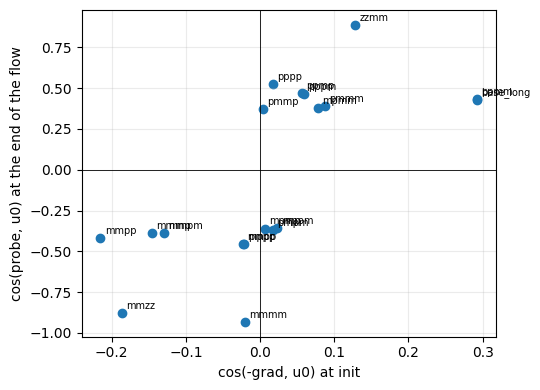

In [5]:
summary = pd.read_csv(RESULTS / "summary.csv")
display(summary[["tag", "signs", "steps", "init_cos_u0", "final_cos_u0", "final_norm_over_eps", "final_level4_energy",
                 "step_to_90pct", "loss_start", "loss_end"]].round(3))
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(summary.init_cos_u0, summary.final_cos_u0)
for r in summary.itertuples():
    ax.annotate(r.tag.replace("signs_", ""), (r.init_cos_u0, r.final_cos_u0), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6); ax.grid(alpha=0.25)
ax.set_xlabel("cos(-grad, u0) at init"); ax.set_ylabel("cos(probe, u0) at the end of the flow")
fig.tight_layout(); plt.show()

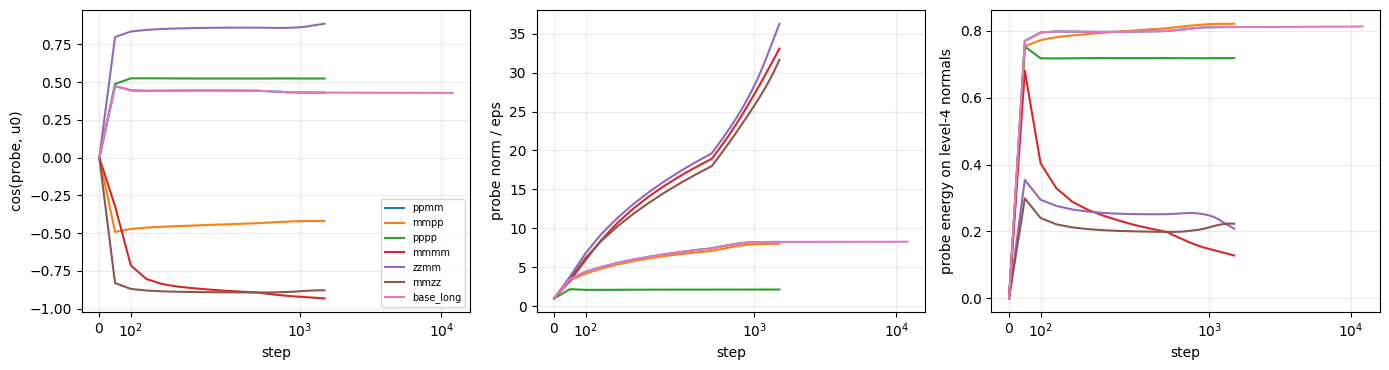

In [6]:
show = ["signs_ppmm", "signs_mmpp", "signs_pppp", "signs_mmmm", "signs_zzmm", "signs_mmzz", "base_long"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for tag in show:
    p = RESULTS / f"traj_{tag}.csv"
    if not p.exists():
        continue
    t = pd.read_csv(p)
    axes[0].plot(t.step, t.cos_u0, label=tag.replace("signs_", ""))
    axes[1].plot(t.step, t.norm / EPS, label=tag.replace("signs_", ""))
    axes[2].plot(t.step, [sum(row[f"cos_u{j}"]**2 for j in range(15, 31)) for _, row in t.iterrows()], label=tag.replace("signs_", ""))
axes[0].set_ylabel("cos(probe, u0)"); axes[1].set_ylabel("probe norm / eps"); axes[2].set_ylabel("probe energy on level-4 normals")
for ax in axes: ax.set_xlabel("step"); ax.grid(alpha=0.25); ax.set_xscale("symlog", linthresh=500)
axes[0].legend(fontsize=7); fig.tight_layout(); plt.show()

## 4. Why the probe stalls, and what lets it through

In the sweep, every pattern that keeps at least one group with probe weight +1 stalls at
|cos| 0.36-0.52 with about 80% of the probe's direction on level-4 normals, and the 12000-step
base run confirms that is a fixed point. The three patterns with no +1 group at all reach
|cos| 0.88-0.93. The explanation: a unit that is on whenever the probe is on gives the probe a
*constant* lens, and a constant lens pulls the probe toward E[y x], which lies on level 4. Only
the input-dependent part of the lens, through units gated by other features relative to the
probe, can pull toward a coarse direction. The cell below tests this by shrinking the inert
groups' probe weight continuously: the endpoint should move from the stall to u_0 as the
constant part of the lens vanishes.

,inert-group probe weight,"init cos(-g,u0)","final cos(probe,u0)",final level-4 energy,final norm/eps,loss end
0,1.00,0.293,0.431,0.811,8.253,0.680
1,0.30,0.238,0.481,0.758,13.468,0.680
2,0.10,0.153,0.889,0.205,17.320,0.678
3,0.03,0.135,0.896,0.192,29.652,0.675
4,0.00,0.128,0.887,0.208,36.277,0.673


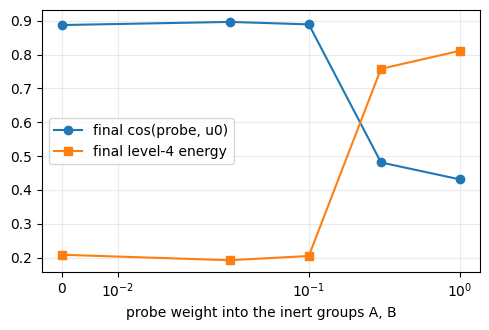

In [7]:
knob_rows = []
for w in [1.0, 0.3, 0.1, 0.03, 0.0]:
    m = build_designed_model(DesignedInitSpec(eps=EPS, seed=0, group_sign=(w, w, -1, -1)), tree)
    g0 = probe_gradient_report(m, x, y, tree, device=DEVICE, per_group=False)["full"]
    out = run_designed_flow(m, x, y, lr=3e-4, steps=1500, snapshot_every=100, device=DEVICE)
    t = neuron_trajectory_table(out, tree); c = t.iloc[-1]
    knob_rows.append({"inert-group probe weight": w, "init cos(-g,u0)": g0["cos_u0"], "final cos(probe,u0)": c.cos_u0,
                      "final level-4 energy": sum(c[f"cos_u{j}"]**2 for j in range(15, 31)), "final norm/eps": c.norm / EPS,
                      "loss end": out["epoch_losses"][-1]})
knob = pd.DataFrame(knob_rows)
display(knob.round(3))
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(knob["inert-group probe weight"], knob["final cos(probe,u0)"], marker="o", label="final cos(probe, u0)")
ax.plot(knob["inert-group probe weight"], knob["final level-4 energy"], marker="s", label="final level-4 energy")
ax.set_xscale("symlog", linthresh=0.03); ax.set_xlabel("probe weight into the inert groups A, B"); ax.grid(alpha=0.25); ax.legend()
fig.tight_layout(); plt.show()

## 5. Layers 3 and 4, and what the learned checkpoints say about wiring

Scale-matched comparison: identity layer 3 with output weights 20 reproduces the random 0/1
layer 3 with unit outputs to three decimals (0.438 vs 0.439 for the base pattern, 0.929 vs
0.932 and 0.965 vs 0.967 for the no-inert patterns). The fan-in randomness is irrelevant at the
root; only the path-sum scale matters, and it sets the flow time per step. The designs below use
identity layer 3 with an explicit output scale for that reason. A balanced-sign output was also
tried and rejected: it gives a near-perfect initial gradient but the probe shrinks to zero as it
aligns, for reasons not understood.

Wiring statistics from the 200 Part B checkpoints, around first-layer neurons aligned to u_0
(|cos| >= 0.8), at the capture step and at loss 0.3. Two questions: are the outgoing weights of
u_0 neurons predominantly negative, and how do units that read two u_0 neurons combine them?

In [8]:
B = Path("../results/init_sweep/partB"); tree_b = load_tree(B / "tree.npz"); Ub = tree_b.w_list
level = np.array([0] + [1]*2 + [2]*4 + [3]*8 + [4]*16)
tab = sweep_capture_table(B)
out_rows, pair_rows = [], []
for r in tab.itertuples():
    run = load_run(r.path); steps = run["snapshot_steps"]
    for when, idx in [("capture", int(np.nonzero(steps == r.winner_step)[0][0])), ("end", len(steps) - 1)]:
        W1 = run["weights"][FIRST_LAYER_KEY][idx]; W2 = run["weights"]["hidden_layers.1.weight"][idx]
        Cm = (W1 / np.linalg.norm(W1, axis=1, keepdims=True)) @ Ub.T
        j = np.abs(Cm).argmax(1); c = Cm[np.arange(len(W1)), j]; node = np.where(np.abs(c) >= 0.8, j, -1)
        for k in range(len(W1)):
            col = W2[:, k]
            out_rows.append({"when": when, "level": int(level[node[k]]) if node[k] >= 0 else -1, "frac_neg": float((col < 0).mean()),
                             "frac_neg_weighted": float(np.abs(col[col < 0]).sum() / np.abs(col).sum()), "mean": float(col.mean())})
        u0s = np.nonzero(node == 0)[0]
        for i, k in enumerate(u0s):
            for k2 in u0s[i + 1:]:
                for v in range(W2.shape[0]):
                    a, b = W2[v, k], W2[v, k2]
                    if abs(a) < 0.1 or abs(b) < 0.1:
                        continue
                    pair_rows.append({"when": when, "same_pole": bool(np.sign(c[k]) == np.sign(c[k2])), "same_sign": bool(np.sign(a) == np.sign(b)), "w": abs(a * b)})
O = pd.DataFrame(out_rows); P = pd.DataFrame(pair_rows)
print("outgoing weights of first-layer neurons by alignment level (-1 = unaligned):")
display(O.groupby(["when", "level"]).agg(n=("frac_neg", "size"), frac_neg=("frac_neg", "mean"), frac_neg_weighted=("frac_neg_weighted", "mean"), mean=("mean", "mean")).round(3))
print("pairs of u_0 neurons read by one unit: fraction with the same weight sign")
display(P.groupby(["when", "same_pole"]).agg(n=("w", "size"), frac_same_sign=("same_sign", "mean"),
        frac_same_sign_weighted=("w", lambda s: (s * P.loc[s.index, "same_sign"]).sum() / s.sum())).round(3))

outgoing weights of first-layer neurons by alignment level (-1 = unaligned):


n  frac_neg  frac_neg_weighted   mean
when    level                                          
capture -1     7280     0.435              0.359  0.025
         0      491     0.482              0.372  0.035
         1      225     0.461              0.369  0.030
         2        4     0.462              0.428  0.015
end     -1     1101     0.459              0.438  0.019
         0      709     0.465              0.499 -0.004
         1      969     0.463              0.451  0.029
         2     1902     0.468              0.454  0.021
         3     3005     0.480              0.474  0.008
         4      314     0.455              0.420  0.019

pairs of u_0 neurons read by one unit: fraction with the same weight sign


n  frac_same_sign  frac_same_sign_weighted
when    same_pole                                                
capture False       2234           0.432                    0.455
        True        2213           0.171                    0.092
end     False      14382           0.344                    0.234
        True        9219           0.646                    0.838

Reading: the outgoing weights of u_0 neurons are about half negative by count and by magnitude,
the same as every other neuron, and layer 3 and the output are half negative too. Sign alone is
not an invariant of the learned nets. What is structured is the pairing: by loss 0.3, a unit that
reads two opposite-pole u_0 neurons gives them opposite signs three quarters of the time by
magnitude, so it computes a linear readout of u_0·x from the ReLU pair. That is the inspiration
for the `linear` cue mode below, which reads each level-4 cue pair as +1 on one sign and -1 on
its twin.

## 6. Two probes, one to +u_0 and one to -u_0

`two_probe_spec`: probe 0 gets C- and D-type groups, probe 1 gets A- and B-type groups, every
probe weight -1, no group shared, identity layer 3, output 20. Rows 0-19 of layer 2 belong to
probe 0 and rows 20-39 to probe 1.

=== cue_mode = relu: logit scale {'rms_logit': 0.23211617767810822, 'max_abs_logit': 0.4804963767528534}


,probe,cos_u0,grad_norm,level4_energy,off_span,group0_cos_u0,group1_cos_u0,group2_cos_u0,group3_cos_u0
0,0,0.048,1.895,0.861,0.136,0.045,0.057,NaN,NaN
1,1,-0.075,1.922,0.857,0.136,NaN,NaN,-0.076,-0.082


=== cue_mode = linear: logit scale {'rms_logit': 0.09127265959978104, 'max_abs_logit': 0.3273330330848694}


,probe,cos_u0,grad_norm,level4_energy,off_span,group0_cos_u0,group1_cos_u0,group2_cos_u0,group3_cos_u0
0,0,0.419,0.994,0.811,0.013,0.355,0.427,NaN,NaN
1,1,-0.430,1.014,0.801,0.014,NaN,NaN,-0.362,-0.445


,cue_mode,probe,final_cos_u0,cos_u0_at_50,final_norm_over_eps,cues_median_norm_over_eps,cues_on_u0,cos_probe0_probe1,loss_end
0,relu,0,0.925,0.704,35.487,3.126,0,-0.944,0.669
1,relu,1,-0.926,-0.722,34.799,3.126,0,-0.944,0.669
2,linear,0,0.903,0.489,47.103,12.399,0,-0.914,0.652
3,linear,1,-0.901,-0.428,45.818,12.399,0,-0.914,0.652


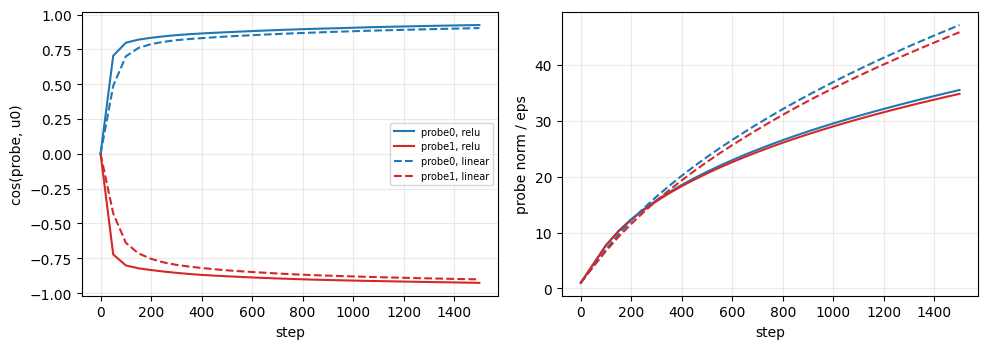

In [9]:
two_rows = []
for cue_mode in ["relu", "linear"]:
    spec2 = two_probe_spec(cue_mode=cue_mode, eps=EPS, seed=0, layer3="identity", output_scale=20.0)
    m2 = build_multiprobe_model(spec2, tree)
    print(f"=== cue_mode = {cue_mode}: logit scale {logit_scale(m2, x, device=DEVICE)}")
    display(multiprobe_gradient_report(m2, spec2, x, y, tree, device=DEVICE).round(3))
    out2 = run_designed_flow(build_multiprobe_model(spec2, tree), x, y, lr=3e-4, steps=1500, snapshot_every=50, device=DEVICE)
    Wend = out2["checkpoint_snapshots"][1500]["hidden_layers.0.weight"].numpy(); nr = np.linalg.norm(Wend, axis=1) / EPS
    cend = Wend @ tree.w_list[0] / np.linalg.norm(Wend, axis=1)
    for pidx in (0, 1):
        t = neuron_trajectory_table(out2, tree, neuron=pidx); t["cue_mode"] = cue_mode; t["probe"] = pidx
        t.to_csv(RESULTS / f"traj_twoprobe_{cue_mode}_probe{pidx}.csv", index=False)
        two_rows.append({"cue_mode": cue_mode, "probe": pidx, "final_cos_u0": float(t.cos_u0.iloc[-1]), "cos_u0_at_50": float(t.cos_u0.iloc[1]),
                         "final_norm_over_eps": float(t.norm.iloc[-1] / EPS), "cues_median_norm_over_eps": float(np.median(nr[2:34])),
                         "cues_on_u0": int((np.abs(cend[2:34]) > 0.8).sum()), "cos_probe0_probe1": float(Wend[0] @ Wend[1] / np.linalg.norm(Wend[0]) / np.linalg.norm(Wend[1])),
                         "loss_end": out2["epoch_losses"][-1]})
two = pd.DataFrame(two_rows); two.to_csv(RESULTS / "summary_twoprobe.csv", index=False)
display(two.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for cue_mode, ls in [("relu", "-"), ("linear", "--")]:
    for pidx, col in [(0, "tab:blue"), (1, "tab:red")]:
        t = pd.read_csv(RESULTS / f"traj_twoprobe_{cue_mode}_probe{pidx}.csv")
        axes[0].plot(t.step, t.cos_u0, ls=ls, color=col, label=f"probe{pidx}, {cue_mode}")
        axes[1].plot(t.step, t.norm / EPS, ls=ls, color=col, label=f"probe{pidx}, {cue_mode}")
axes[0].set_ylabel("cos(probe, u0)"); axes[1].set_ylabel("probe norm / eps")
for ax in axes: ax.set_xlabel("step"); ax.grid(alpha=0.25)
axes[0].legend(fontsize=7); fig.tight_layout(); plt.show()

## 7. Six probes: +-u_0, +-u_1, +-u_2

`node_probe_groups(probe, node, pole)` generalizes the root pairs. For a unit gated on a level-4
cue of sign s under a child of node a on side `side` (-1 left, +1 right), the push on the probe
toward u_a has sign `-s * side` with a -1 probe weight. So pole +1 pairs negative-side cues under
the right child with positive-side cues under the left child, pole -1 the reverse. Both children
lie on the same side of every ancestor, so the pair's ancestor pushes cancel, and using every cue
under each child cancels the descendant pushes. `six_probe_spec` uses groups of 4 for the root
probes and 3 for the node probes: 6 probes, 32 cues, 2 random neurons, 40 second-layer rows.

The runs come from `results/designed_init/run_six_probe.py`: relu vs linear cues, cues free vs
frozen (via the trainer's parameter update mask), 1500 and 6000 steps.

In [10]:
six = pd.read_csv(RESULTS / "summary_six_probe.csv")
print("t = 0: cosine of each probe's negative gradient with its signed target, and with u_0 (ancestor leakage)")
init_tab = pd.concat([pd.read_csv(RESULTS / f"init_{t}.csv") for t in ("six_relu", "six_linear")])
display(init_tab.pivot(index="target", columns="tag", values=["cos_target", "cos_u0"]).round(3))
print("end of flow:")
display(six.pivot(index="target", columns="tag", values="final_cos_target").round(2)[["six_relu", "six_linear", "six_linear_long", "six_relu_frozen", "six_linear_frozen", "six_linear_frozen_long"]])
print("u_0 leakage at the end (cos with u_0; for the root probes this is the target itself):")
display(six.pivot(index="target", columns="tag", values="final_cos_u0").round(2)[["six_relu", "six_linear", "six_linear_long", "six_relu_frozen", "six_linear_frozen", "six_linear_frozen_long"]])
display(six.groupby("tag").agg(steps=("steps", "first"), cues_frozen=("cues_frozen", "first"), cues_with_coarse_top_node=("cues_coarse_top", "first"),
                              cues_median_norm_over_eps=("cues_median_norm_over_eps", "first"), loss_end=("loss_end", "first")).round(3))

t = 0: cosine of each probe's negative gradient with its signed target, and with u_0 (ancestor leakage)


cos_target              cos_u0         
tag    six_linear six_relu six_linear six_relu
target                                        
+u0         0.421    0.050      0.421    0.050
+u1         0.347    0.150      0.002   -0.004
+u2         0.355    0.158      0.013    0.006
-u0         0.431    0.077     -0.431   -0.077
-u1         0.353    0.163     -0.001   -0.000
-u2         0.346    0.152     -0.009   -0.008

end of flow:


tag,six_relu,six_linear,six_linear_long,six_relu_frozen,six_linear_frozen,six_linear_frozen_long
target,,,,,,
+u0,0.89,0.87,0.93,0.33,0.62,0.64
+u1,0.04,0.60,0.54,0.31,0.51,0.52
+u2,0.55,0.62,0.47,0.36,0.51,0.52
-u0,0.87,0.78,0.91,0.34,0.63,0.66
-u1,0.19,0.56,0.54,0.35,0.51,0.52
-u2,0.01,0.59,0.60,0.33,0.51,0.54


u_0 leakage at the end (cos with u_0; for the root probes this is the target itself):


tag,six_relu,six_linear,six_linear_long,six_relu_frozen,six_linear_frozen,six_linear_frozen_long
target,,,,,,
+u0,0.89,0.87,0.93,0.33,0.62,0.64
+u1,0.72,0.22,0.38,-0.05,-0.08,-0.06
+u2,-0.45,-0.21,-0.47,0.01,0.06,0.02
-u0,-0.87,-0.78,-0.91,-0.34,-0.63,-0.66
-u1,0.66,0.26,0.39,-0.03,-0.07,-0.04
-u2,-0.75,-0.27,-0.35,-0.01,0.06,0.06


,steps,cues_frozen,cues_with_coarse_top_node,cues_median_norm_over_eps,loss_end
tag,,,,,
six_linear,1500,False,0,10.486,0.663
six_linear_frozen,1500,True,0,1.000,0.689
six_linear_frozen_long,6000,True,0,1.000,0.689
six_linear_long,6000,False,14,18.816,0.654
six_relu,1500,False,18,2.821,0.674
six_relu_frozen,1500,True,0,1.000,0.688


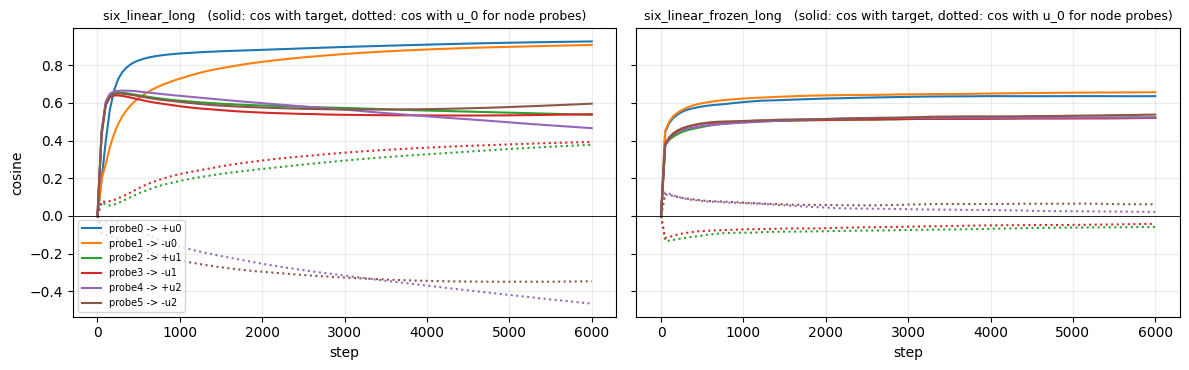

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, tag in zip(axes, ["six_linear_long", "six_linear_frozen_long"]):
    T = pd.read_csv(RESULTS / f"traj_{tag}.csv")
    for pidx, g in T.groupby("probe"):
        ax.plot(g.step, g.cos_target, label=f"probe{pidx} -> {'+' if g.target_pole.iloc[0] > 0 else '-'}u{g.target_node.iloc[0]}")
        ax.plot(g.step, g.cos_u0 if g.target_node.iloc[0] != 0 else np.nan * g.step, ls=":", color=ax.lines[-1].get_color())
    ax.set_title(f"{tag}   (solid: cos with target, dotted: cos with u_0 for node probes)", fontsize=9)
    ax.set_xlabel("step"); ax.grid(alpha=0.25); ax.axhline(0, color="k", lw=0.6)
axes[0].set_ylabel("cosine"); axes[0].legend(fontsize=7)
fig.tight_layout(); plt.show()

## 8. The full hierarchy: two probes per internal node, trained with SGD

`HierarchyDesignSpec`: 30 probes (rows 0-29, two per node 0..14), 32 cues (rows 30-61, each
+-u_j plus a random off-span component of relative size 0.2), 18 random neurons; widths
(80, 40, 40). Each probe owns 4 / 2 / 1 / 1 second-layer units by the target's level, each unit
reading a random subset of the balanced cue set (at least one cue per child). Layers 2-4 keep the
{-1,0,+1} / {0,1} / ones sign structure scaled to order-one row norms, eps = 0.01.

Training: batch 1000, SGD lr 0.02, momentum 0.9, stop at trailing loss 0.3 or 100k steps.
Conditions: relu vs linear cues, cue rows free vs frozen; 12 design seeds each. Produced by
`results/designed_init/run_hierarchy.py`.

In [12]:
H = Path("../results/designed_init/hierarchy")
hs = pd.read_csv(H / "summary.csv")
print(f"{len(hs)} runs; stopped by loss: {(hs.stopped_by == 'stop_loss').sum()}, by step cap: {(hs.stopped_by == 'max_steps').sum()}")
cols_end = [f"on_target_L{l}_end" for l in range(4)] + [f"cos_target_L{l}_end" for l in range(4)]
agg = hs.groupby(["cue_mode", "cues_frozen"]).agg(n=("tag", "size"), final_loss=("final_loss", "mean"), loss_10k=("loss_10k", "mean"), loss_30k=("loss_30k", "mean"),
                                                   **{c: (c, "mean") for c in cols_end}, cues_coarse=("cues_coarse_top_end", "mean"), random_coarse=("random_coarse_aligned_end", "mean"))
display(agg.round(3).T)
print("spread across seeds of the level-1 on-target fraction at the end:")
display(hs.groupby(["cue_mode", "cues_frozen"])["on_target_L1_end"].agg(["min", "median", "max"]).round(2))

48 runs; stopped by loss: 0, by step cap: 48


cue_mode           linear            relu        
cues_frozen         False   True    False   True 
n                  12.000  12.000  12.000  12.000
final_loss          0.402   0.425   0.404   0.426
loss_10k            0.600   0.616   0.604   0.605
loss_30k            0.458   0.474   0.458   0.471
on_target_L0_end    0.958   1.000   0.708   1.000
on_target_L1_end    0.375   1.000   0.188   1.000
on_target_L2_end    0.240   0.927   0.271   0.958
on_target_L3_end    0.120   0.380   0.141   0.297
cos_target_L0_end   0.955   0.999   0.707   0.999
cos_target_L1_end   0.376   0.998   0.182   0.998
cos_target_L2_end   0.222   0.927   0.267   0.945
cos_target_L3_end   0.091   0.406   0.144   0.365
cues_coarse        24.250   0.000  20.000   0.000
random_coarse       5.833  14.417   7.417  14.667

spread across seeds of the level-1 on-target fraction at the end:


min  median   max
cue_mode cues_frozen                   
linear   False        0.0    0.38  0.75
         True         1.0    1.00  1.00
relu     False        0.0    0.25  0.50
         True         1.0    1.00  1.00

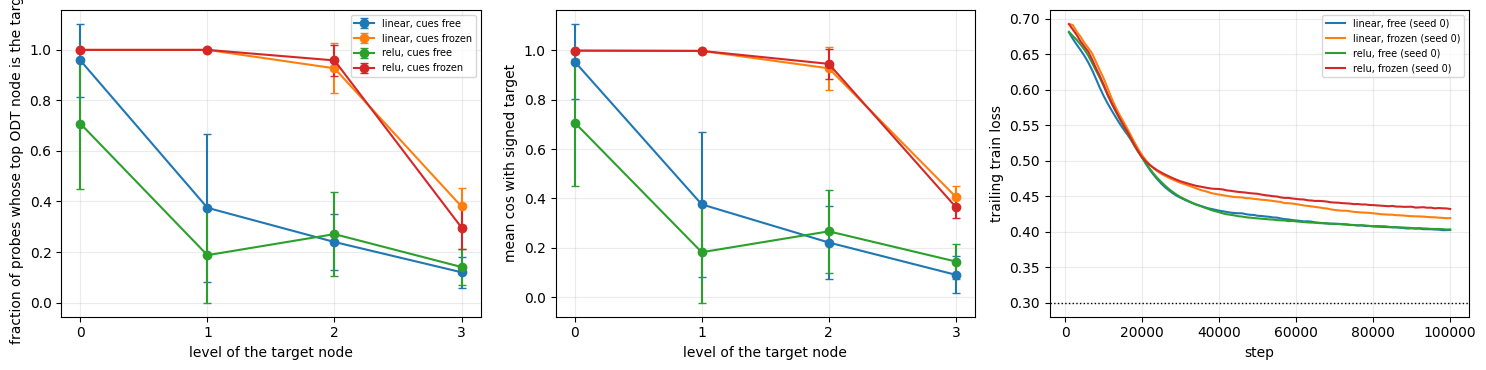

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for (cm, fz), g in hs.groupby(["cue_mode", "cues_frozen"]):
    label = f"{cm}, cues {'frozen' if fz else 'free'}"
    for lab, xs in [("10k", 10), ("30k", 30), ("end", 100)]:
        pass
    axes[0].errorbar(range(4), [g[f"on_target_L{l}_end"].mean() for l in range(4)], yerr=[g[f"on_target_L{l}_end"].std() for l in range(4)], marker="o", capsize=3, label=label)
    axes[1].errorbar(range(4), [g[f"cos_target_L{l}_end"].mean() for l in range(4)], yerr=[g[f"cos_target_L{l}_end"].std() for l in range(4)], marker="o", capsize=3, label=label)
axes[0].set_ylabel("fraction of probes whose top ODT node is the target"); axes[1].set_ylabel("mean cos with signed target")
for ax in axes[:2]: ax.set_xlabel("level of the target node"); ax.set_xticks(range(4)); ax.grid(alpha=0.25)
axes[0].legend(fontsize=7)
# loss curves for seed 0 of each condition
from layer_lenses.init_sweep import load_run
for (cm, fz), g in hs.groupby(["cue_mode", "cues_frozen"]):
    r = load_run(H / "runs" / f"{g.tag.iloc[0]}.npz")
    axes[2].plot(r["snapshot_steps"], r["snapshot_loss"], label=f"{cm}, {'frozen' if fz else 'free'} (seed {g.design_seed.iloc[0]})")
axes[2].axhline(0.3, color="k", ls=":", lw=1); axes[2].set_xlabel("step"); axes[2].set_ylabel("trailing train loss"); axes[2].grid(alpha=0.25); axes[2].legend(fontsize=7)
fig.tight_layout(); plt.show()

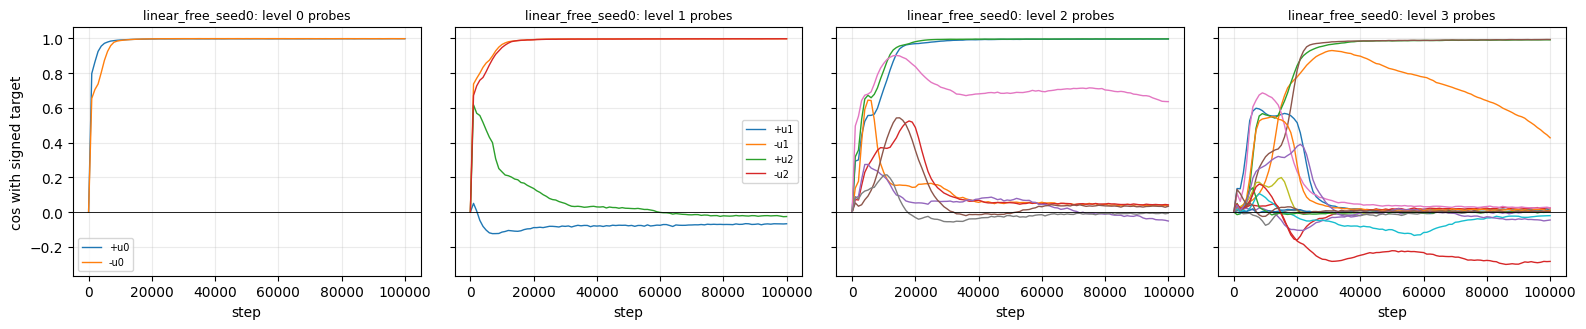

In [14]:
# Per-probe view for one run: cosine with target over steps, one panel per level
run_tag = hs[(hs.cue_mode == "linear") & (~hs.cues_frozen)].tag.iloc[0]
r = load_run(H / "runs" / f"{run_tag}.npz"); tree_h = tree
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for i, W1 in enumerate(r["weights"]["hidden_layers.0.weight"]):
    t = hierarchy_probe_table(W1, tree_h); t["step"] = r["snapshot_steps"][i]
    if i == 0: acc = t
    else: acc = pd.concat([acc, t], ignore_index=True)
for lvl, ax in enumerate(axes):
    for pidx, g in acc[acc.level == lvl].groupby("probe"):
        ax.plot(g.step, g.cos_target, lw=1, label=g.target.iloc[0])
    ax.set_title(f"{run_tag}: level {lvl} probes", fontsize=9); ax.set_xlabel("step"); ax.grid(alpha=0.25); ax.axhline(0, color="k", lw=0.6)
    if lvl <= 1: ax.legend(fontsize=7)
axes[0].set_ylabel("cos with signed target")
fig.tight_layout(); plt.show()

## 9. Releasing the cues at 10k steps, and a wider second layer

Two follow-ups from `results/designed_init/run_hierarchy2.py`. First, the frozen conditions
rerun with the 32 cue rows released at step 10k, after the probes for levels 0-2 have
committed (12 seeds, both cue modes). Second, the second layer widened from 40 to 120 units,
giving 12 / 6 / 3 / 3 units per probe by level instead of 4 / 2 / 1 / 1, one seed, both cue
modes, cues free / frozen / released at 10k. Same training settings and 100k-step cap.

In [15]:
U1 = pd.read_csv(Path("../results/designed_init/hierarchy_unfreeze/summary.csv"))
base = hs.copy(); base["cues"] = np.where(base.cues_frozen, "frozen", "free")
both = pd.concat([base[base.width2.isna() if "width2" in base else np.ones(len(base), bool)].assign(width2=40), U1], ignore_index=True)
lv = lambda lab: [f"on_target_L{l}_{lab}" for l in range(4)]
print("width 40, means over 12 seeds: on-target fraction by level at 10k and at the end, loss at the end, cue drift")
summ = both.groupby(["cue_mode", "cues"]).agg(n=("tag", "size"), final_loss=("final_loss", "mean"),
        **{c: (c, "mean") for c in lv("10k") + lv("end")}, cues_coarse_end=("cues_coarse_top_end", "mean")).round(3)
display(summ.T)
print("unfreeze runs: on-target by level right before release (10k), at 30k, and at the end")
display(U1.groupby("cue_mode")[lv("10k") + lv("30k") + lv("end")].mean().round(2).T)

width 40, means over 12 seeds: on-target fraction by level at 10k and at the end, loss at the end, cue drift


cue_mode          linear                        relu                    
cues                free  frozen unfreeze10k    free  frozen unfreeze10k
n                 12.000  12.000      12.000  12.000  12.000      12.000
final_loss         0.402   0.425       0.399   0.404   0.426       0.403
on_target_L0_10k   0.958   1.000       1.000   0.708   1.000       1.000
on_target_L1_10k   0.438   1.000       1.000   0.188   1.000       1.000
on_target_L2_10k   0.240   0.990       0.990   0.229   0.990       0.990
on_target_L3_10k   0.052   0.354       0.354   0.115   0.042       0.042
on_target_L0_end   0.958   1.000       1.000   0.708   1.000       1.000
on_target_L1_end   0.375   1.000       1.000   0.188   1.000       1.000
on_target_L2_end   0.240   0.927       0.969   0.271   0.958       0.990
on_target_L3_end   0.120   0.380       0.609   0.141   0.297       0.432
cues_coarse_end   24.250   0.000      14.833  20.000   0.000      11.250

unfreeze runs: on-target by level right before release (10k), at 30k, and at the end


cue_mode,linear,relu
on_target_L0_10k,1.00,1.00
on_target_L1_10k,1.00,1.00
on_target_L2_10k,0.99,0.99
on_target_L3_10k,0.35,0.04
on_target_L0_30k,1.00,1.00
on_target_L1_30k,1.00,1.00
on_target_L2_30k,0.98,0.99
on_target_L3_30k,0.62,0.44
on_target_L0_end,1.00,1.00
on_target_L1_end,1.00,1.00


seed 0: second-layer width 40 vs 120


final_loss  loss_30k  on_target_L0_end  \
cue_mode cues        width2                                           
linear   free        40           0.403     0.448               1.0   
                     120          0.419     0.462               0.5   
         frozen      40           0.419     0.469               1.0   
                     120          0.434     0.473               1.0   
         unfreeze10k 40           0.401     0.453               1.0   
                     120          0.392     0.430               1.0   
relu     free        40           0.403     0.449               1.0   
                     120          0.413     0.454               0.5   
         frozen      40           0.432     0.471               1.0   
                     120          0.434     0.476               1.0   
         unfreeze10k 40           0.403     0.466               1.0   
                     120          0.395     0.461               1.0   

                             on_target_L1_end  on_target_L2_end  \
cue_mode cues        width2                                       
linear   free        40                  0.50             0.250   
                     120                 0.75             0.500   
         frozen      40                  1.00             1.000   
                     120                 1.00             1.000   
         unfreeze10k 40                  1.00             1.000   
                     120                 1.00             1.000   
relu     free        40                  0.00             0.125   
                     120                 0.00             0.250   
         frozen      40                  1.00             0.875   
                     120                 1.00             0.875   
         unfreeze10k 40                  1.00             0.875   
                     120                 1.00             0.875   

                             on_target_L3_end  cues_coarse_top_end  
cue_mode cues        width2                                         
linear   free        40                 0.125                   25  
                     120                0.062                   18  
         frozen      40                 0.312                    0  
                     120                0.375                    0  
         unfreeze10k 40                 0.562                   12  
                     120                0.500                   17  
relu     free        40                 0.062                   18  
                     120                0.062                   18  
         frozen      40                 0.375                    0  
                     120                0.250                    0  
         unfreeze10k 40                 0.375                   10  
                     120                0.250                   14

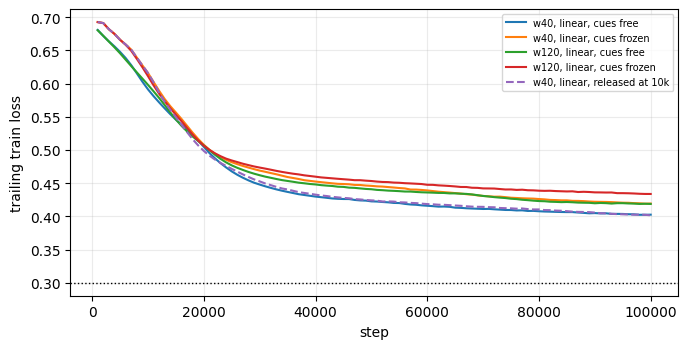

In [16]:
W = pd.read_csv(Path("../results/designed_init/hierarchy_w120/summary.csv"))
ref = both[both.design_seed == 0][["cue_mode", "cues", "final_loss", "loss_30k"] + lv("end") + ["cues_coarse_top_end"]].assign(width2=40)
cmp = pd.concat([ref, W[["cue_mode", "cues", "final_loss", "loss_30k"] + lv("end") + ["cues_coarse_top_end", "width2"]]], ignore_index=True)
print("seed 0: second-layer width 40 vs 120")
display(cmp.sort_values(["cue_mode", "cues", "width2"]).set_index(["cue_mode", "cues", "width2"]).round(3))
fig, ax = plt.subplots(figsize=(7, 3.6))
from layer_lenses.init_sweep import load_run
for d, lab in [("hierarchy", "w40"), ("hierarchy_w120", "w120")]:
    for cues in ("free", "frozen"):
        tag = f"linear_{'free' if cues == 'free' else 'frozen'}_seed0" if lab == "w40" else f"linear_{cues}_w120_seed0"
        r = load_run(Path("../results/designed_init") / d / "runs" / f"{tag}.npz")
        ax.plot(r["snapshot_steps"], r["snapshot_loss"], label=f"{lab}, linear, cues {cues}")
r = load_run(Path("../results/designed_init/hierarchy_unfreeze/runs/linear_unfreeze10k_seed0.npz")); ax.plot(r["snapshot_steps"], r["snapshot_loss"], ls="--", label="w40, linear, released at 10k")
ax.axhline(0.3, color="k", ls=":", lw=1); ax.set_xlabel("step"); ax.set_ylabel("trailing train loss"); ax.grid(alpha=0.25); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

## 10. The same design at standard-init scale

`standard_scale_spec(scheme)` keeps every sign pattern and rescales every row of every layer to
the norm a standard random init would give: `"default"` is the model's own init (std 1/sqrt(3 fan_in),
row norm 0.577), `"kaiming"` is std sqrt(2/fan_in), row norm 1.41. The first layer is then at
standard size rather than eps = 0.01, so this is no longer a small perturbation of zero; it asks
whether the wiring works from an init a standard scheme could plausibly have produced. Linear
cues, seed 0, cues free / frozen / released at 10k, same SGD settings and cap. From
`results/designed_init/run_hierarchy_scale.py`.

final_loss  final_step stopped_by  \
scheme                  cues                                             
eps=0.01 (sections 8-9) free              0.403      100000  max_steps   
                        frozen            0.419      100000  max_steps   
                        unfreeze10k       0.401      100000  max_steps   
default                 free              0.422      100000  max_steps   
                        frozen            0.430      100000  max_steps   
                        unfreeze10k       0.414      100000  max_steps   
kaiming                 free              0.297       34000  stop_loss   
                        frozen            0.288       37000  stop_loss   
                        unfreeze10k       0.299       46000  stop_loss   

                                     on_target_L0_end  on_target_L1_end  \
scheme                  cues                                              
eps=0.01 (sections 8-9) free                      1.0              0.50   
                        frozen                    1.0              1.00   
                        unfreeze10k               1.0              1.00   
default                 free                      1.0              1.00   
                        frozen                    1.0              0.50   
                        unfreeze10k               1.0              0.50   
kaiming                 free                      1.0              0.75   
                        frozen                    1.0              0.50   
                        unfreeze10k               1.0              0.50   

                                     on_target_L2_end  on_target_L3_end  \
scheme                  cues                                              
eps=0.01 (sections 8-9) free                    0.250             0.125   
                        frozen                  1.000             0.312   
                        unfreeze10k             1.000             0.562   
default                 free                    0.250             0.062   
                        frozen                  0.375             0.312   
                        unfreeze10k             0.000             0.062   
kaiming                 free                    0.625             0.188   
                        frozen                  0.875             0.625   
                        unfreeze10k             0.500             0.375   

                                     cues_coarse_top_end  row_norm  \
scheme                  cues                                         
eps=0.01 (sections 8-9) free                          25     0.010   
                        frozen                         0     0.010   
                        unfreeze10k                   12     0.010   
default                 free                          23     0.577   
                        frozen                         0     0.577   
                        unfreeze10k                   21     0.577   
kaiming                 free                          23     1.414   
                        frozen                         0     1.414   
                        unfreeze10k                   15     1.414   

                                     logit_rms_init  
scheme                  cues                         
eps=0.01 (sections 8-9) free                    NaN  
                        frozen                  NaN  
                        unfreeze10k             NaN  
default                 free                  0.067  
                        frozen                0.067  
                        unfreeze10k           0.067  
kaiming                 free                  2.397  
                        frozen                2.397  
                        unfreeze10k           2.397

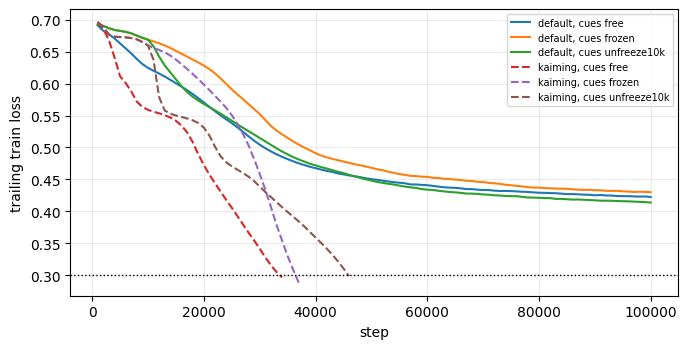

In [17]:
S = pd.read_csv(Path("../results/designed_init/hierarchy_scale/summary.csv"))
ref40 = both[(both.design_seed == 0) & (both.cue_mode == "linear")][["cues", "final_loss", "final_step", "stopped_by"] + lv("end") + ["cues_coarse_top_end"]].assign(scheme="eps=0.01 (sections 8-9)", row_norm=0.01)
cmp_s = pd.concat([ref40, S[["scheme", "cues", "row_norm", "logit_rms_init", "final_loss", "final_step", "stopped_by"] + lv("end") + ["cues_coarse_top_end"]]], ignore_index=True)
display(cmp_s.set_index(["scheme", "cues"]).round(3))
fig, ax = plt.subplots(figsize=(7, 3.6))
for r in S.itertuples():
    run = load_run(Path("../results/designed_init/hierarchy_scale/runs") / f"{r.tag}.npz")
    ax.plot(run["snapshot_steps"], run["snapshot_loss"], label=f"{r.scheme}, cues {r.cues}", ls="-" if r.scheme == "default" else "--")
ax.axhline(0.3, color="k", ls=":", lw=1); ax.set_xlabel("step"); ax.set_ylabel("trailing train loss"); ax.grid(alpha=0.25); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

## 11. Kaiming scale halved, more seeds, trained toward loss 0.05

Every row of every layer at norm 0.707 (Kaiming's 1.41 divided by 2), linear cues, seeds 0-3,
cues free versus frozen-then-released at 10k. Constant-LR SGD as before (batch 1000, lr 0.02,
momentum 0.9), stopping at trailing loss 0.05 or 600k steps, whole sweep capped at 110 minutes.
From `results/designed_init/run_hierarchy_kaiming_half.py`. `step_to_x` is the first snapshot
(every 2000 steps) whose trailing loss is at or below x; -1 means never.

8 runs; stopped by loss 0.05: 0, by cap: 8


,cues,design_seed,logit_rms_init,final_step,stopped_by,final_loss,min_loss,step_to_0.3,step_to_0.2,step_to_0.1,step_to_0.05
0,free,0,0.150,600000,max_steps,0.373,0.373,-1,-1,-1,-1
2,free,1,0.152,600000,max_steps,0.380,0.380,-1,-1,-1,-1
4,free,2,0.152,600000,max_steps,0.376,0.376,-1,-1,-1,-1
6,free,3,0.152,600000,max_steps,0.377,0.377,-1,-1,-1,-1
1,unfreeze10k,0,0.150,600000,max_steps,0.384,0.384,-1,-1,-1,-1
3,unfreeze10k,1,0.152,600000,max_steps,0.383,0.383,-1,-1,-1,-1
5,unfreeze10k,2,0.152,600000,max_steps,0.383,0.383,-1,-1,-1,-1
7,unfreeze10k,3,0.152,600000,max_steps,0.382,0.382,-1,-1,-1,-1


on-target fraction by level at 10k / 100k / end, and cue drift:


cues,free,unfreeze10k
on_target_L0_10k,1.00,1.00
on_target_L1_10k,1.00,1.00
on_target_L2_10k,0.88,0.69
on_target_L3_10k,0.94,0.70
on_target_L0_100k,1.00,1.00
on_target_L1_100k,0.56,0.62
on_target_L2_100k,0.28,0.22
on_target_L3_100k,0.17,0.06
on_target_L0_end,1.00,1.00
on_target_L1_end,0.56,0.62


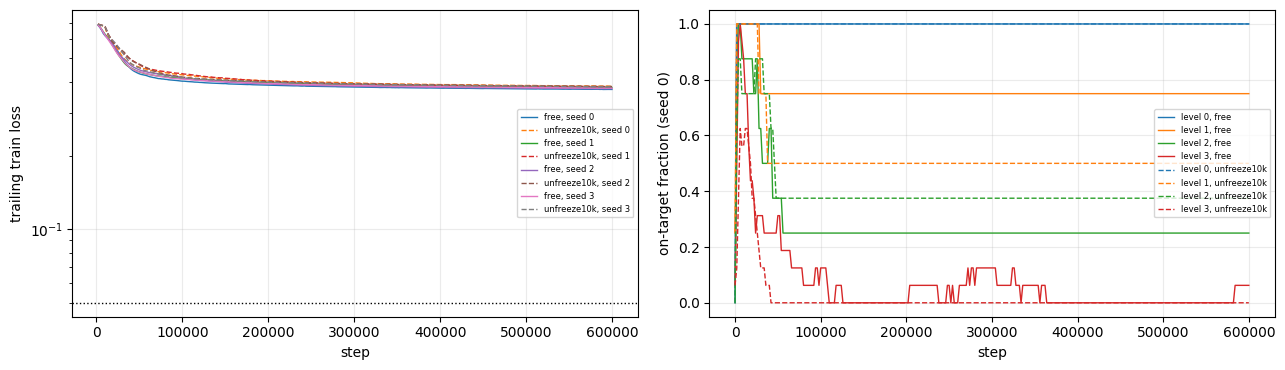

In [18]:
K = pd.read_csv(Path("../results/designed_init/hierarchy_kaiming_half/summary.csv"))
print(f"{len(K)} runs; stopped by loss 0.05: {(K.stopped_by == 'stop_loss').sum()}, by cap: {(K.stopped_by == 'max_steps').sum()}")
cols = ["cues", "design_seed", "logit_rms_init", "final_step", "stopped_by", "final_loss", "min_loss", "step_to_0.3", "step_to_0.2", "step_to_0.1", "step_to_0.05"]
display(K[cols].sort_values(["cues", "design_seed"]).round(3))
print("on-target fraction by level at 10k / 100k / end, and cue drift:")
display(K.groupby("cues")[[f"on_target_L{l}_10k" for l in range(4)] + [f"on_target_L{l}_100k" for l in range(4)] + lv("end") + ["cues_coarse_top_end"]].mean().round(2).T)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for r in K.itertuples():
    run = load_run(Path("../results/designed_init/hierarchy_kaiming_half/runs") / f"{r.tag}.npz")
    axes[0].plot(run["snapshot_steps"], run["snapshot_loss"], ls="-" if r.cues == "free" else "--", label=f"{r.cues}, seed {r.design_seed}", lw=1)
    acc = []
    for i, W1 in enumerate(run["weights"]["hidden_layers.0.weight"]):
        t = hierarchy_probe_table(W1, tree); acc.append({"step": run["snapshot_steps"][i], **{f"L{l}": float((g.top_node == g.node).mean()) for l, g in t.groupby("level")}})
    acc = pd.DataFrame(acc)
    if r.design_seed == 0:
        for l in range(4):
            axes[1].plot(acc.step, acc[f"L{l}"], ls="-" if r.cues == "free" else "--", color=f"C{l}", label=f"level {l}, {r.cues}", lw=1)
axes[0].set_yscale("log"); axes[0].axhline(0.05, color="k", ls=":", lw=1); axes[0].set_xlabel("step"); axes[0].set_ylabel("trailing train loss"); axes[0].grid(alpha=0.25); axes[0].legend(fontsize=6)
axes[1].set_xlabel("step"); axes[1].set_ylabel("on-target fraction (seed 0)"); axes[1].grid(alpha=0.25); axes[1].legend(fontsize=6)
fig.tight_layout(); plt.show()

## 12. One long Kaiming run per cue treatment, with cosine annealing

Kaiming row norms (1.41 in every layer), linear cues, seed 0, cues free versus frozen for the
whole run. Trained with `train_relu_mlp`: 1000 epochs of batch 1000 (1M steps), lr 0.02 annealed
by cosine to 0.001, momentum 0.9, fixed batch order. Snapshots of all layers every 10 epochs;
test error on a fresh 200k sample. From `results/designed_init/run_hierarchy_kaiming_cosine.py`.

,0,1
cues,free,frozen
logit_rms_init,2.3969,2.3969
final_epoch_loss,0.0078,0.0104
min_epoch_loss,0.0078,0.0104
train_log_loss_end,0.0072,0.0096
test_error_end,0.0064,0.0067
epoch_to_0.3,35,37
epoch_to_0.2,52,51
epoch_to_0.1,120,135
epoch_to_0.05,318,317


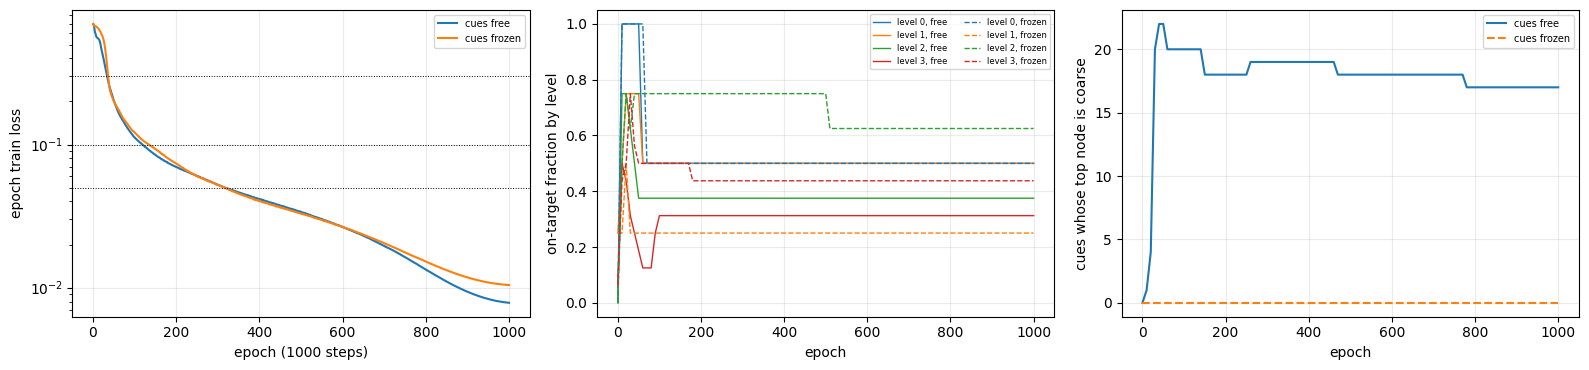

In [19]:
KC = Path("../results/designed_init/hierarchy_kaiming_cosine")
kc = pd.read_csv(KC / "summary.csv")
display(kc[["cues", "logit_rms_init", "final_epoch_loss", "min_epoch_loss", "train_log_loss_end", "test_error_end",
            "epoch_to_0.3", "epoch_to_0.2", "epoch_to_0.1", "epoch_to_0.05"] + [f"on_target_L{l}_ep10" for l in range(4)] + [f"on_target_L{l}_end" for l in range(4)] + ["cues_coarse_top_end", "wall_min"]].round(4).T)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for r in kc.itertuples():
    z = np.load(KC / "runs" / f"{r.tag}.npz"); pe = pd.read_csv(KC / f"per_epoch_{r.tag}.csv")
    axes[0].plot(np.arange(1, len(z["epoch_losses"]) + 1), z["epoch_losses"], label=f"cues {r.cues}")
    for l in range(4):
        axes[1].plot(pe.epoch, pe[f"on_target_L{l}"], color=f"C{l}", ls="-" if r.cues == "free" else "--", label=f"level {l}, {r.cues}", lw=1)
    axes[2].plot(pe.epoch, pe.cues_coarse_top, ls="-" if r.cues == "free" else "--", label=f"cues {r.cues}")
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch (1000 steps)"); axes[0].set_ylabel("epoch train loss"); axes[0].grid(alpha=0.25); axes[0].legend(fontsize=7)
for thr in (0.3, 0.1, 0.05): axes[0].axhline(thr, color="k", ls=":", lw=0.7)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("on-target fraction by level"); axes[1].grid(alpha=0.25); axes[1].legend(fontsize=6, ncol=2)
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("cues whose top node is coarse"); axes[2].grid(alpha=0.25); axes[2].legend(fontsize=7)
fig.tight_layout(); plt.show()

aligned  aligned_probes  aligned_cues  aligned_random  \
cues   epoch                                                          
free   10           1               1             0               0   
       50          42               7            26               9   
       100         52              16            24              12   
       300         61              24            23              14   
       1000        60              24            22              14   
frozen 10          32               0            32               0   
       50          64              17            32              15   
       100         73              26            32              15   
       300         75              27            32              16   
       1000        76              28            32              16   

              nodes_covered  covered_L0  covered_L1  covered_L2  covered_L3  \
cues   epoch                                                                  
free   10                 1           1           0           0           0   
       50                22           1           2           4           7   
       100               30           1           2           4           8   
       300               31           1           2           4           8   
       1000              31           1           2           4           8   
frozen 10                16           0           0           0           0   
       50                31           1           2           4           8   
       100               31           1           2           4           8   
       300               31           1           2           4           8   
       1000              31           1           2           4           8   

              covered_L4  
cues   epoch              
free   10              0  
       50              8  
       100            15  
       300            16  
       1000           16  
frozen 10             16  
       50             16  
       100            16  
       300            16  
       1000           16

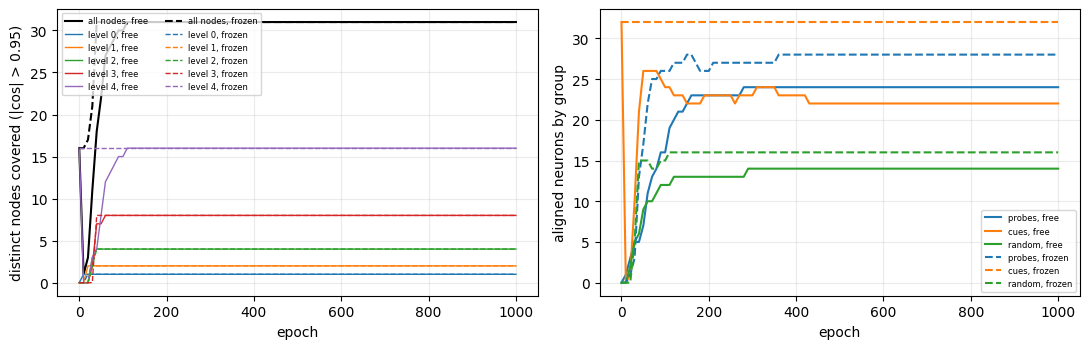

In [20]:
from layer_lenses.designed_init import NODE_LEVEL
# Node coverage: first-layer neurons with |cos| > 0.95 to some tree normal, and how many distinct nodes they cover.
# Per-probe on-target undercounts what is learned: a probe that leaves its node is replaced by another neuron.
groups = {"probes": range(0, 30), "cues": range(30, 62), "random": range(62, 80)}
cov_rows = []
for r in kc.itertuples():
    z = np.load(KC / "runs" / f"{r.tag}.npz"); W = z["w__hidden_layers.0.weight"]
    for i, e in enumerate(z["epochs"]):
        W1 = W[i]; C = (W1 / np.linalg.norm(W1, axis=1, keepdims=True)) @ tree.w_list.T
        top = np.abs(C).argmax(1); aligned = np.abs(C).max(1) > 0.95; covered = set(top[aligned])
        cov_rows.append({"cues": r.cues, "epoch": int(e), "aligned": int(aligned.sum()), **{f"aligned_{g}": int(aligned[list(ix)].sum()) for g, ix in groups.items()},
                         "nodes_covered": len(covered), **{f"covered_L{l}": len([n for n in covered if NODE_LEVEL[n] == l]) for l in range(5)}})
cov = pd.DataFrame(cov_rows)
display(cov[cov.epoch.isin([10, 50, 100, 300, 1000])].set_index(["cues", "epoch"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for cues, g in cov.groupby("cues"):
    ls = "-" if cues == "free" else "--"
    axes[0].plot(g.epoch, g.nodes_covered, ls=ls, color="k", label=f"all nodes, {cues}")
    for l in range(5):
        axes[0].plot(g.epoch, g[f"covered_L{l}"], ls=ls, color=f"C{l}", lw=1, label=f"level {l}, {cues}")
    for k, grp in enumerate(groups):
        axes[1].plot(g.epoch, g[f"aligned_{grp}"], ls=ls, color=f"C{k}", label=f"{grp}, {cues}")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("distinct nodes covered (|cos| > 0.95)"); axes[0].grid(alpha=0.25); axes[0].legend(fontsize=6, ncol=2)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("aligned neurons by group"); axes[1].grid(alpha=0.25); axes[1].legend(fontsize=6)
fig.tight_layout(); plt.show()


['linear_free_kaiming_cosine_seed0', 'linear_frozen_kaiming_cosine_seed0']


Text(0.5, 1.0, 'Training Loss over Epochs for Free Cues')

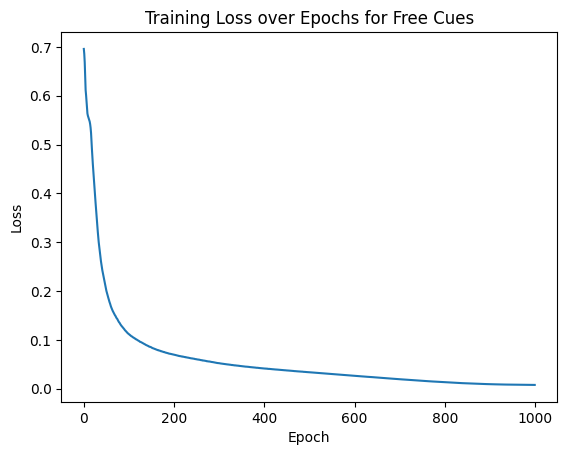

In [21]:
# human gen
tags=[]
for r in kc.itertuples():
    tags.append(r.tag)
print(tags)
z_freecues = np.load(KC / "runs" / f"{tags[0]}.npz")
z_frozencues = np.load(KC / "runs" / f"{tags[1]}.npz")

z=z_freecues

plt.plot(z["epoch_losses"]);
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss over Epochs for Free Cues")


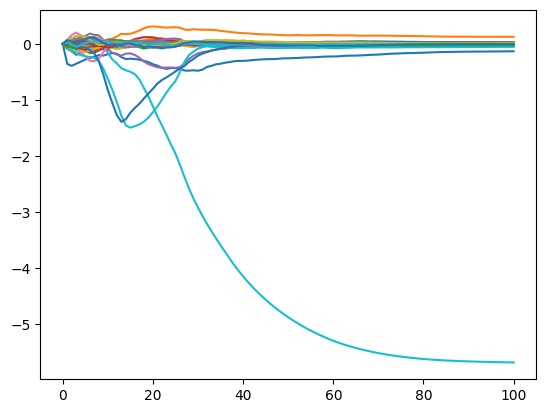

In [22]:
W0 = z["w__hidden_layers.0.weight"]
W1 = z["w__hidden_layers.1.weight"]
W2 = z["w__hidden_layers.2.weight"]
W3 = z["w__output_layer.weight"]

components = (W0@tree.w_list.T)
neuron_id=1
ODT_node =  2
plt.plot(components[:,neuron_id,:]);

## 13. Inspecting the cosine-annealed checkpoints

Tools for the stored trajectories in `hierarchy_kaiming_cosine/runs/*.npz` (all four weight
matrices every 10 epochs). `snapshot_state_dict` turns one snapshot into a state dict, which
`plot_layered_relu_graph` draws with each first-layer neuron labelled by its closest ODT node.
`first_layer_alignment_series` tracks the cosines of chosen first-layer neurons to chosen ODT
nodes over the whole run, with the neuron norm and its fan-out norm (norm of its outgoing
column in the second-layer weight). Edit the parameters at the top of each cell.

First-layer neuron ids in this design: probes 0-29 (two per internal node 0-14, in the order of
`HIERARCHY_TARGETS`: probe 2k is +u_k, probe 2k+1 is -u_k), cues 30-61, random 62-79.


Visible edges: 679 / 4840
First-layer aligned nodes: 75 / 80


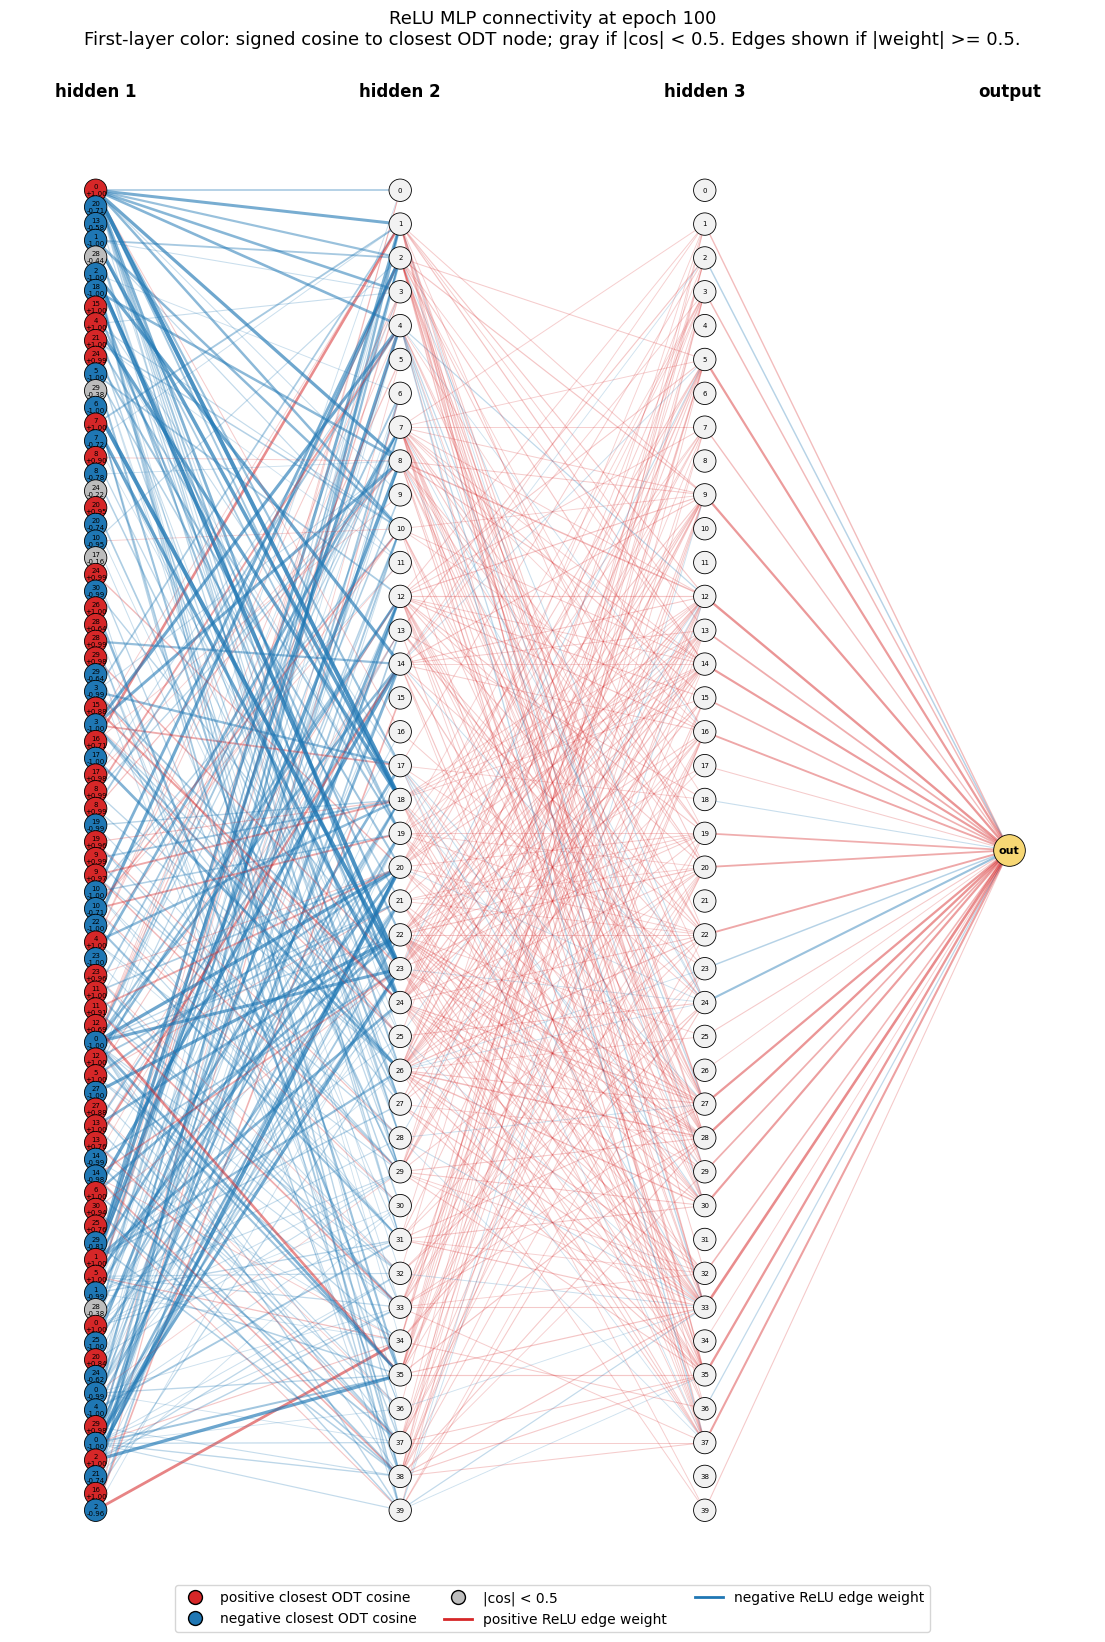

In [23]:
from layer_lenses.relu_analysis import (plot_layered_relu_graph, snapshot_state_dict, state_dict_from_weight_arrays,
                                         first_layer_alignment_series, plot_first_layer_alignment_series, first_layer_odt_alignment)

RUN_CUES = "free"          # "free" or "frozen"
GRAPH_EPOCH = 100          # any multiple of 10 in 0..1000
ALIGN_THRESHOLD = 0.5      # first-layer neuron coloured only if |cos| to its closest node exceeds this
EDGE_THRESHOLD = 0.5       # edges drawn only if |weight| exceeds this
ONLY_ALIGNED_FIRST_LAYER = True   # hide edges out of first-layer neurons below ALIGN_THRESHOLD

run = np.load(KC / "runs" / f"linear_{RUN_CUES}_kaiming_cosine_seed0.npz")
sd = snapshot_state_dict(run, GRAPH_EPOCH)
node_mask = None
if ONLY_ALIGNED_FIRST_LAYER:
    al = first_layer_odt_alignment(state_dict=sd, tree=tree)
    node_mask = [al["max_abs_cos"].numpy() >= ALIGN_THRESHOLD] + [np.ones(sd[f"hidden_layers.{i}.weight"].shape[0], dtype=bool) for i in (1, 2)]
alignment, visible_edges, fig, ax = plot_layered_relu_graph(state_dict=sd, tree=tree, depth=5, epoch=GRAPH_EPOCH, node_mask=node_mask,
                                                            alignment_abs_threshold=ALIGN_THRESHOLD, edge_abs_threshold=EDGE_THRESHOLD, figsize=(14, 20))
plt.show()


In [24]:
# Which node each first-layer neuron sits on at GRAPH_EPOCH, grouped by neuron type (probe / cue / random).
lab = pd.DataFrame({"neuron": np.arange(80), "group": ["probe"] * 30 + ["cue"] * 32 + ["random"] * 18,
                    "closest_node": alignment["closest_odt_np"], "level": alignment["node_level"],
                    "signed_cos": alignment["signed_closest_cos"].numpy().round(3), "norm": alignment["row_norms"].numpy().round(2)})
lab["designed_target"] = [HIERARCHY_TARGETS[i] if i < 30 else "" for i in range(80)]
display(lab[lab.signed_cos.abs() >= ALIGN_THRESHOLD].sort_values(["level", "closest_node", "signed_cos"]).reset_index(drop=True))


,neuron,group,closest_node,level,signed_cos,norm,designed_target
0,51,cue,0,0,-0.999,8.48,
1,75,random,0,0,-0.999,7.70,
2,72,random,0,0,-0.995,4.03,
3,68,random,0,0,0.995,4.51,
4,0,probe,0,0,1.000,11.41,"(0, 1)"
...,...,...,...,...,...,...,...
70,29,probe,29,4,-0.640,1.13,"(14, -1)"
71,28,probe,29,4,0.983,2.10,"(14, 1)"
72,74,random,29,4,0.984,2.46,
73,24,probe,30,4,-0.990,2.94,"(12, 1)"


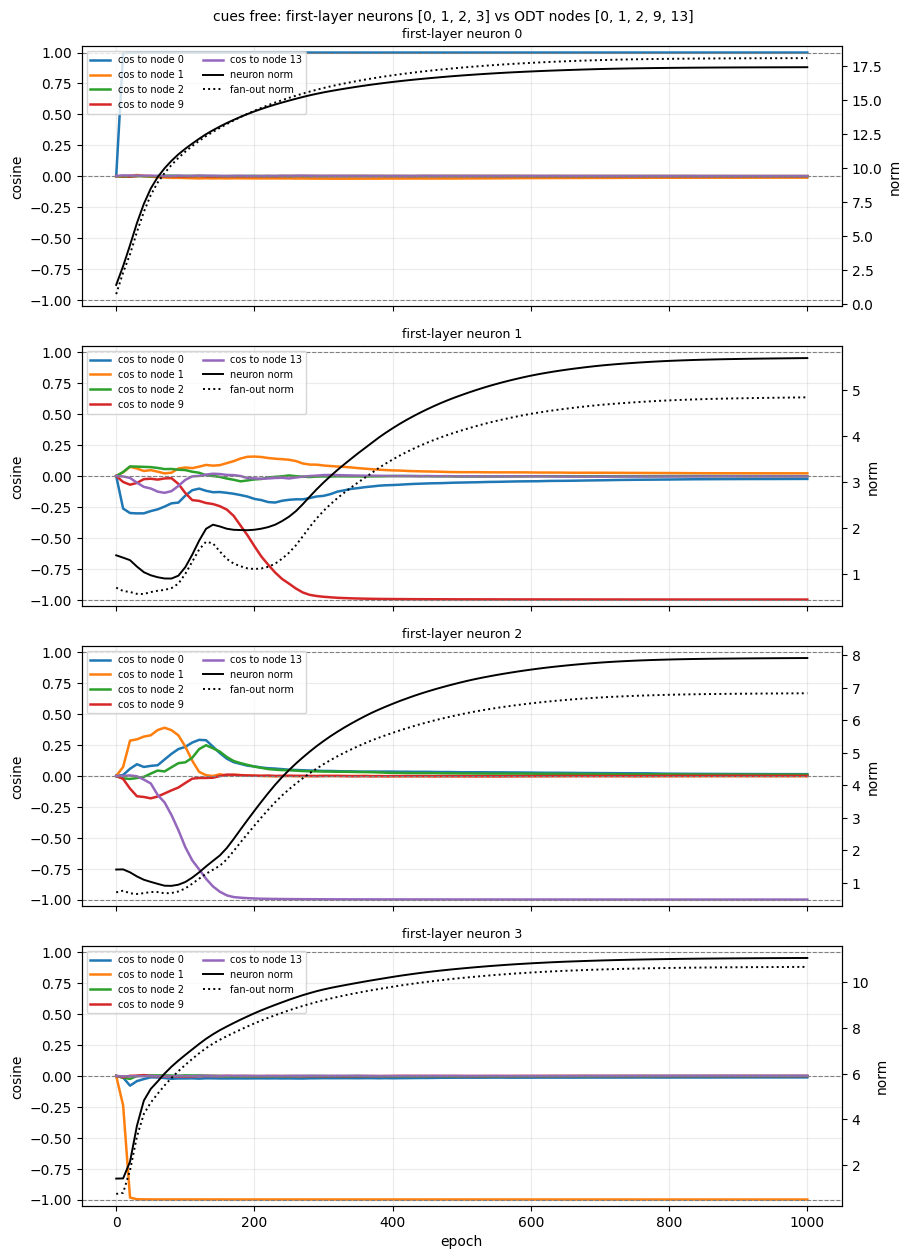

,,norm,cos_0,cos_1,cos_2,cos_9,cos_13,fan_out_norm
neuron,epoch,,,,,,,
0,0,1.414,0.000,-0.000,0.000,-0.000,-0.000,0.739
1,0,1.414,-0.000,0.000,-0.000,0.000,-0.000,0.714
2,0,1.414,-0.000,0.000,-0.000,-0.000,0.000,0.713
3,0,1.414,0.000,0.000,-0.000,0.000,0.000,0.744
0,10,2.789,0.993,-0.006,-0.003,0.000,0.005,2.318
1,10,1.364,-0.263,0.030,0.032,-0.048,-0.003,0.642
2,10,1.419,0.008,0.073,-0.019,-0.024,0.000,0.764
3,10,1.422,-0.013,-0.238,-0.013,-0.011,-0.003,0.793
0,50,8.488,0.999,-0.005,-0.002,0.001,0.002,8.008


In [25]:
# Cosines of chosen first-layer neurons to chosen ODT nodes along the run, with the neuron norm and fan-out norm on the right axis.
SERIES_CUES = "free"
NEURON_IDS = [0, 1, 2, 3]          # e.g. the two root probes and the two +-u_1 probes
NODE_IDS = [0, 1, 2, 9, 13]        # u_0, u_1, u_2 and the nodes the drifting probes ended on
EPOCH_RANGE = (0, 1000)

run_s = np.load(KC / "runs" / f"linear_{SERIES_CUES}_kaiming_cosine_seed0.npz")
sel = (run_s["epochs"] >= EPOCH_RANGE[0]) & (run_s["epochs"] <= EPOCH_RANGE[1])
series = first_layer_alignment_series(run_s["w__hidden_layers.0.weight"][sel], run_s["epochs"][sel], tree,
                                      neuron_ids=NEURON_IDS, node_ids=NODE_IDS, fan_out_weights=run_s["w__hidden_layers.1.weight"][sel])
fig, axes = plot_first_layer_alignment_series(series, title=f"cues {SERIES_CUES}: first-layer neurons {NEURON_IDS} vs ODT nodes {NODE_IDS}")
plt.show()
display(series[series.epoch.isin([0, 10, 50, 100, 300, 1000])].round(3).set_index(["neuron", "epoch"]))
